In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/bureau_balance_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/HomeCredit_columns_description.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/instalments_payments_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/POS_CASH_balance_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/bureau_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/previous_application_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/application_train_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/credit_card_balance_sample.csv


# Notebook Purpose

Đây là notebook được dùng để xây dựng nên các Pipeline chính thức để xử lý dữ liệu và huấn luyện model, các Pipeline này đã tuân theo đúng nguyên tắc fit train, transform validate, test, từ đó giúp ngăn chặn DataLeakage.

Luồng xử lý dữ liệu của DataPipeline ; bên dưới sẽ là quy trình để xây dựng nên DataPipeline như trong hình minh hoạ, tuân thủ đúng theo nguyên tắc fit train, transform validate, test để ngăn Data Leakage

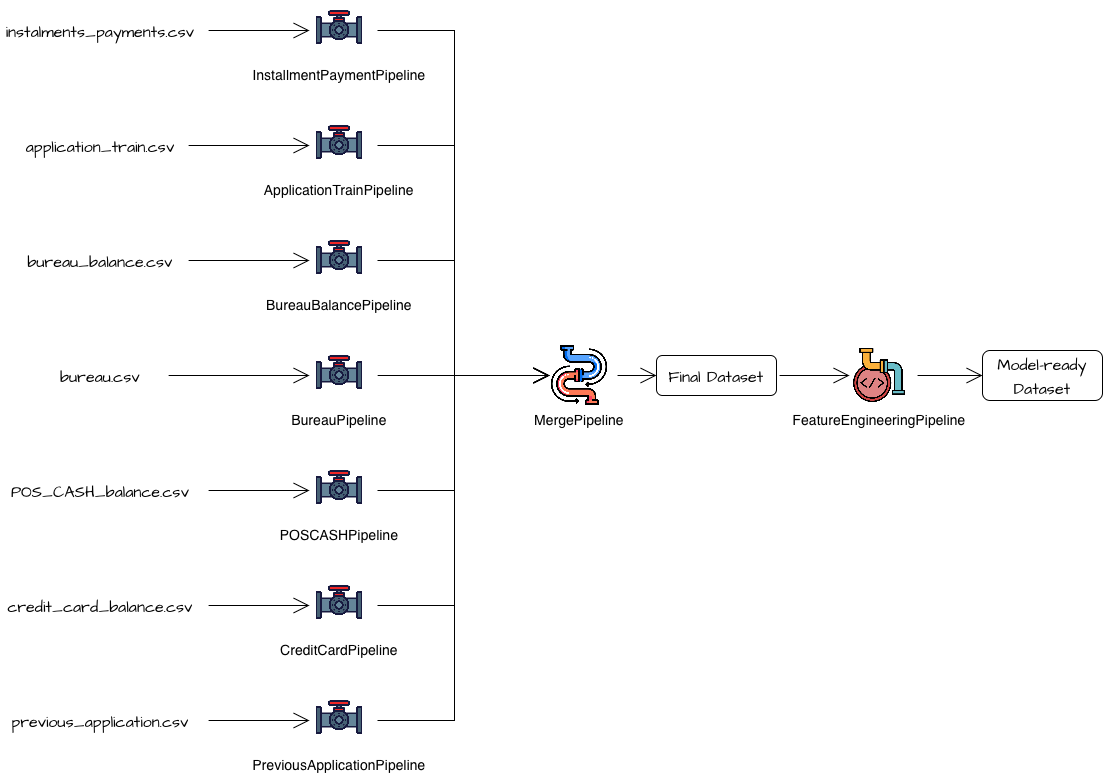

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import matplotlib.ticker as mticker
import math
import itertools
from typing import Literal
from matplotlib.ticker import FuncFormatter
from matplotlib.axes import Axes
from matplotlib.figure import Figure
import seaborn.objects as so
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [3]:
from sklearn import set_config
set_config(transform_output='pandas', display='diagram')

In [4]:
application_train = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/application_train_sample.csv')
bureau = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/bureau_sample.csv')
bureau_balance = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/bureau_balance_sample.csv')
credit_card_balance = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/credit_card_balance_sample.csv')
installments_payments = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/instalments_payments_sample.csv')
previous_application = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/previous_application_sample.csv')
POS_CASH_balance = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/POS_CASH_balance_sample.csv')

In [5]:
from sklearn.model_selection import train_test_split

X = application_train.drop(columns=['TARGET'])
y = application_train['TARGET']

# chia tập dữ liệu cho application_train
X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, stratify=y_train, test_size=0.2, random_state=42)

application_train_train = pd.concat([X_train, y_train], axis=1)
application_train_val = pd.concat([X_val, y_val], axis=1)
application_train_test = pd.concat([X_test, y_test], axis=1)

SK_ID_CURR_train = X_train['SK_ID_CURR'].values
SK_ID_CURR_val = X_val['SK_ID_CURR'].values
SK_ID_CURR_test = X_test['SK_ID_CURR'].values

# chia tập dữ liệu cho bureau
bureau_train = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_train)]
bureau_val = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_val)]
bureau_test = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_test)]

SK_ID_BUREAU_train = bureau_train['SK_ID_BUREAU'].values
SK_ID_BUREAU_val = bureau_val['SK_ID_BUREAU'].values
SK_ID_BUREAU_test = bureau_test['SK_ID_BUREAU'].values

# chia tập dữ liệu cho previous_application
previous_application_train = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_train)]
previous_application_val = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_val)]
previous_application_test = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_test)]

SK_ID_PREV_train = previous_application_train['SK_ID_PREV'].values
SK_ID_PREV_val = previous_application_val['SK_ID_PREV'].values
SK_ID_PREV_test = previous_application_test['SK_ID_PREV'].values

# chia tập dữ liệu cho bureau_balance
bureau_balance_train = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_train)]
bureau_balance_val = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_val)]
bureau_balance_test = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_test)]

# chia tập dữ liệu cho POS_CASH_balance
filter_pos_cash_train = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_pos_cash_val = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_pos_cash_test = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_test))

POS_CASH_balance_train = POS_CASH_balance[filter_pos_cash_train]
POS_CASH_balance_val = POS_CASH_balance[filter_pos_cash_val]
POS_CASH_balance_test = POS_CASH_balance[filter_pos_cash_test]

# chia tập dữ liệu cho instalments_payments
filter_instalments_train = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_instalments_val = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_instalments_test = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_test))

installments_payments_train = installments_payments[filter_instalments_train]
installments_payments_val = installments_payments[filter_instalments_val]
installments_payments_test = installments_payments[filter_instalments_test]

# chia tập dữ liệu cho credit_card_balance
filter_credit_train = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_credit_val = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_credit_test = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_test))

credit_card_balance_train = credit_card_balance[filter_credit_train]
credit_card_balance_val = credit_card_balance[filter_credit_val]
credit_card_balance_test = credit_card_balance[filter_credit_test]

# Định nghĩa Custom Transformer

In [6]:
class AddPrefix(BaseEstimator, TransformerMixin):
    def __init__(self, prefix:str, exclude:list[str]):
        """
        Used to add prefix to columns' name
        
        Args:
            prefix: prefix added to columns' name
            exclude: columns that don't need prefix
        """
        self.prefix = prefix
        self.exclude = exclude

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        self.new_cols_name_ = [
            col if col in self.exclude else f'{self.prefix}_{col}'
            for col in X_copy.columns
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.columns = self.new_cols_name_
        return X_copy

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.new_cols_name_

In [7]:
class RemoveFeature(BaseEstimator, TransformerMixin):
    def __init__(self, columns_removed:list[str]):
        """
        columns_removed: columns which will be removed from dataset
        """
        self.columns_removed = columns_removed

    def fit(self, X:pd.DataFrame, y=None):
        missing = set(self.columns_removed) - set(X.columns) # check if columns's name removed is misspelled
        if missing:
            raise ValueError(f"Các cột sau không tồn tại trong dữ liệu: {missing}")
        
        # Giữ nguyên thứ tự cột gốc, chỉ loại bỏ cột cần xóa
        self.columns_selected_ = [
            col for col in X.columns if col not in self.columns_removed
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_new = X_copy[self.columns_selected_]
        return X_new

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.columns_selected_

In [8]:
class Aggeration(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols:list[str], num_cols:list[str], groupby_col:str):
        """
        Used to perform aggregation by specific columns, num_cols and cat_cols will have differenct aggregation
        
        Args:
            cat_cols: categorical column's name
            num_cols: numerical column's name
            groupby_col: specific column's name used for groupby to perform aggregation
        """
        if groupby_col in num_cols:
            num_cols.remove(groupby_col)

        self.cat_cols = cat_cols
        self.num_cols = num_cols
        self.groupby_col = groupby_col

    def _build_agg_dict(self):
        agg_dict = {}
        for col in self.cat_cols:
            agg_dict[col] = ['mean'] # ['sum', 'mean']
        for col in self.num_cols:
            agg_dict[col] = ['mean', 'max'] # ['min', 'max', 'mean']
        return agg_dict
    
    def fit(self, X:pd.DataFrame, y=None):
        agg_dict = self._build_agg_dict()
        self.new_cols_name_ = [self.groupby_col] + [
            f'{col}_{stat.lower()}' for col, stats in agg_dict.items() for stat in stats
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        agg_dict = self._build_agg_dict()

        X_agg = X_copy.groupby(self.groupby_col).agg(agg_dict)
        X_agg.columns = self.new_cols_name_[1:]
        X_agg.reset_index(inplace=True)
        
        return X_agg

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.new_cols_name_

In [9]:
class FrequencyGrouping(BaseEstimator, TransformerMixin):
    def __init__(self, threshold = 0.999999):
        self.threshold = threshold
    
    def fit(self, X: pd.DataFrame, y=None):
        X_copy = X.copy()
        self.dict_categories_ = {}
        columns = X_copy.columns

        for col in columns:
            col: str
            frequency = X_copy[col].value_counts(normalize=True)
            cum_frequency = np.cumsum(frequency)

            kept_categories = frequency[cum_frequency <= self.threshold].index.tolist()
            self.dict_categories_[col] = kept_categories

        return self
    
    def transform(self, X: pd.DataFrame):
        X_copy = X.copy()
        
        for col, kept_categories in self.dict_categories_.items():
            col: str
            kept_categories: list
            X_copy[col] = X_copy[col].apply(lambda x: x if x in kept_categories else 'Others')

        return X_copy

# Xây dựng các Pipeline cho từng tập dữ liệu

## Cho Application Train

### Ver 1

In [10]:
from sklearn.preprocessing import OrdinalEncoder
class ApplicationTrainPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_application_train = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)
        
        self.missing_ratio_feature_removed_application_train_ = RemoveFeature(columns_removed = columns_remove_application_train)
        X_copy = self.missing_ratio_feature_removed_application_train_.fit_transform(X_copy)

        # encode for categorical features
        obj_columns = list(X_copy.select_dtypes('object').columns)
        self.categorical_encoder_ = ColumnTransformer(
            transformers=[
                ('ordinal_encoding', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan), obj_columns)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.categorical_encoder_.fit_transform(X_copy)

        # auto detect binary features having ratio < 0.1 or ratio > 1 - 0.1, to remove them
        all_cols = list(X_copy.columns)
        binary_columns = [col for col in all_cols if set(X_copy[col].dropna().unique()).issubset({0, 1})]
        binary_columns_mean = X_copy[binary_columns].mean()
        binary_columns_remove = list(
            binary_columns_mean[(binary_columns_mean < 0.02) |
                         (binary_columns_mean > 1 - 0.02)].index
        )
        # binary_columns_remove.remove('TARGET')

        self.binary_feature_removed_application_train_ = RemoveFeature(columns_removed = binary_columns_remove)
        X_copy = self.binary_feature_removed_application_train_.fit_transform(X_copy)

        self.application_train_add_prefix_ = AddPrefix(prefix='AT', exclude=['SK_ID_CURR'])
        X_copy = self.application_train_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_final = self.missing_ratio_feature_removed_application_train_.transform(X_copy)
        X_final = self.categorical_encoder_.transform(X_final)
        X_final = self.binary_feature_removed_application_train_.transform(X_final)
        X_final = self.application_train_add_prefix_.transform(X_final)
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.application_train_add_prefix_.get_feature_names_out()

### Ver 2

In [11]:
# from sklearn.preprocessing import OneHotEncoder

# class ApplicationTrainPipeline(BaseEstimator, TransformerMixin):
#     def __init__(self):
#         pass

#     def fit(self, X:pd.DataFrame, y=None):
#         X_copy = X.copy()

#         # auto detect features with missing ratio > 0.1, to remove them
#         missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
#         missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
#         columns_remove_application_train = list(missing_ratio[missing_ratio['missing_ratio'] > 0.1].index)
        
#         self.missing_ratio_feature_removed_application_train_ = RemoveFeature(columns_removed = columns_remove_application_train)
#         X_copy = self.missing_ratio_feature_removed_application_train_.fit_transform(X_copy)

#         # encode for categorical features
#         obj_columns = list(X_copy.select_dtypes('object').columns)
#         cat_pipeline = Pipeline([
#             ('frequency_grouping', FrequencyGrouping()),
#             ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
#         ])
        
#         self.cat_cols_transformer_ = ColumnTransformer(
#             transformers=[
#                 ('cat_processing', cat_pipeline, obj_columns)
#             ],
#             remainder='passthrough',
#             verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
#             # force_int_remainder_cols=False
#         )
#         X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

#         # auto detect binary features having ratio < 0.1 or ratio > 1 - 0.1, to remove them
#         all_cols = list(X_copy.columns)
#         binary_columns = [col for col in all_cols if set(X_copy[col].dropna().unique()).issubset({0, 1})]
#         binary_columns_mean = X_copy[binary_columns].mean()
#         binary_columns_remove = list(
#             binary_columns_mean[(binary_columns_mean < 0.1) |
#                          (binary_columns_mean > 1 - 0.1)].index
#         )
#         binary_columns_remove.remove('TARGET')

#         self.binary_feature_removed_application_train_ = RemoveFeature(columns_removed = binary_columns_remove)
#         X_copy = self.binary_feature_removed_application_train_.fit_transform(X_copy)

#         self.application_train_add_prefix_ = AddPrefix(prefix='AT', exclude=['SK_ID_CURR'])
#         X_copy = self.application_train_add_prefix_.fit_transform(X_copy)
        
#         return self

#     def transform(self, X:pd.DataFrame):
#         X_copy = X.copy()
        
#         X_final = self.missing_ratio_feature_removed_application_train_.transform(X_copy)
#         X_final = self.cat_cols_transformer_.transform(X_final)
#         X_final = self.binary_feature_removed_application_train_.transform(X_final)
#         X_final = self.application_train_add_prefix_.transform(X_final)
        
#         return X_final

#     def get_feature_names_out(self, input_features=None):
#         return self.application_train_add_prefix_.get_feature_names_out()

## Cho Bureau_balance

In [12]:
class BureauBalancePipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        cat_cols = list(X_copy.select_dtypes(include=['object']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_BUREAU')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.bureau_balance_add_prefix_ = AddPrefix(prefix='BB', exclude=['SK_ID_BUREAU'])
        X_copy = self.bureau_balance_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_final = self.cat_cols_transformer_.transform(X_copy)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.bureau_balance_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.bureau_balance_add_prefix_.get_feature_names_out()

## Cho POS_CASH_balance

In [13]:
class POSCASHPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        cat_cols = list(X_copy.select_dtypes(include=['object']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)
        
        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)
        
        self.pos_cash_add_prefix_ = AddPrefix(prefix='PC', exclude=['SK_ID_PREV'])
        X_copy = self.pos_cash_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.cat_cols_transformer_.transform(X_copy)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.pos_cash_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.pos_cash_add_prefix_.get_feature_names_out()

## Cho Installment Payments

In [14]:
class InstallmentPaymentPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        cat_cols = list(X_copy.select_dtypes(include=['object']).columns) # empty list
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)
        
        self.aggregate_ = Aggeration(cat_cols=cat_cols, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.installment_payment_add_prefix_ = AddPrefix(prefix='IP', exclude=['SK_ID_PREV'])
        X_copy = self.installment_payment_add_prefix_.fit_transform(X_copy)

        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.aggregate_.transform(X_copy)
        X_final = self.installment_payment_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.installment_payment_add_prefix_.get_feature_names_out()

## Cho Credit Card Balance

In [15]:
class CreditCardPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_credit_card = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)

        self.feature_removed_credit_card_ = RemoveFeature(columns_removed = columns_remove_credit_card)
        X_copy = self.feature_removed_credit_card_.fit_transform(X_copy)

        cat_cols = list(X_copy.select_dtypes(include=['object']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.credit_card_add_prefix_ = AddPrefix(prefix='CC', exclude=['SK_ID_PREV'])
        X_copy = self.credit_card_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.feature_removed_credit_card_.transform(X_copy)
        X_final = self.cat_cols_transformer_.transform(X_final)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.credit_card_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.credit_card_add_prefix_.get_feature_names_out()

## Cho Bureau

In [16]:
class BureauPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_bureau = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)

        self.feature_removed_bureau_ = RemoveFeature(columns_removed = columns_remove_bureau)
        X_copy = self.feature_removed_bureau_.fit_transform(X_copy)

        self.bureau_add_prefix_ = AddPrefix(prefix='B', exclude=['SK_ID_CURR', 'SK_ID_BUREAU'])
        X_copy = self.bureau_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        
        X_final = self.feature_removed_bureau_.transform(X_copy)
        X_final = self.bureau_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.bureau_add_prefix_.get_feature_names_out()

## Cho Previous_application

In [17]:
class PreviousApplicationPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_previous_application = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)
        
        self.feature_removed_previous_application_ = RemoveFeature(columns_removed = columns_remove_previous_application)
        X_copy = self.feature_removed_previous_application_.fit_transform(X_copy)

        self.previous_application_add_prefix_ = AddPrefix(prefix='PA', exclude=['SK_ID_CURR', 'SK_ID_PREV'])
        X_copy = self.previous_application_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        
        X_final = self.feature_removed_previous_application_.transform(X_copy)
        X_final = self.previous_application_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.previous_application_add_prefix_.get_feature_names_out()

# Xây dựng MergePipeline

In [18]:
class MergePipeline:
    def __init__(self):
        self.bureau_balance_pipeline = BureauBalancePipeline()
        self.installment_payment_pipeline = InstallmentPaymentPipeline()
        self.pos_cash_pipeline = POSCASHPipeline()
        self.credit_card_pipeline = CreditCardPipeline()
        self.previous_application_pipeline = PreviousApplicationPipeline()
        self.bureau_pipeline = BureauPipeline()
        self.application_pipeline = ApplicationTrainPipeline()

        # Lưu các transformer/aggregator theo tên nhóm, thay vì tạo nhiều thuộc tính rời rạc
        self.group_transformers_ = {}

    def _encode_and_aggregate_fit(self, df: pd.DataFrame, group_name: str, groupby_col: str = 'SK_ID_CURR'):
        """
        Dùng khi fit: one-hot encode + aggregate cho 1 nhóm bảng (bureau hoặc previous_application),
        đồng thời lưu lại các transformer đã fit để dùng lại lúc transform.
        """
        cat_cols = list(df.select_dtypes(include=['object']).columns)
        num_cols = list(df.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        cat_transformer = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False,
        )
        df_encoded = cat_transformer.fit_transform(df)

        cat_cols_after_onehot = [
            col for col in df_encoded.columns
            if col.startswith(tuple(f"{c}_" for c in cat_cols))
        ]

        aggregator = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col=groupby_col)
        df_agg = aggregator.fit_transform(df_encoded)

        # Lưu lại để transform() dùng sau này
        self.group_transformers_[group_name] = {
            'cat_transformer': cat_transformer,
            'aggregator': aggregator,
        }

        return df_agg

    def _encode_and_aggregate_transform(self, df: pd.DataFrame, group_name: str):
        """Dùng khi transform: áp dụng lại transformer đã fit cho nhóm tương ứng."""
        transformers = self.group_transformers_[group_name]
        df_encoded = transformers['cat_transformer'].transform(df)
        df_agg = transformers['aggregator'].transform(df_encoded)
        return df_agg

    def fit(self, bureau_balance:pd.DataFrame, POS_CASH_balance:pd.DataFrame, application_train:pd.DataFrame,
             credit_card_balance:pd.DataFrame, previous_application:pd.DataFrame, bureau:pd.DataFrame, installments_payments:pd.DataFrame):

        bureau_balance_transform = self.bureau_balance_pipeline.fit_transform(bureau_balance)
        installments_payments_transform = self.installment_payment_pipeline.fit_transform(installments_payments)
        POS_CASH_balance_transform = self.pos_cash_pipeline.fit_transform(POS_CASH_balance)
        credit_card_balance_transform = self.credit_card_pipeline.fit_transform(credit_card_balance)
        previous_application_transform = self.previous_application_pipeline.fit_transform(previous_application)
        bureau_transform = self.bureau_pipeline.fit_transform(bureau)
        application_train_transform = self.application_pipeline.fit_transform(application_train)

        # --- Nhóm bureau ---
        merge_bureau = bureau_transform.merge(bureau_balance_transform, on='SK_ID_BUREAU', how='left')
        merge_bureau.drop(columns=['SK_ID_BUREAU'], inplace=True)
        merge_bureau = self._encode_and_aggregate_fit(merge_bureau, group_name='bureau')

        # --- Nhóm previous_application ---
        merge_prev = previous_application_transform.merge(credit_card_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(POS_CASH_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(installments_payments_transform, on='SK_ID_PREV', how='left')
        merge_prev.drop(columns=['SK_ID_PREV'], inplace=True)
        merge_prev = self._encode_and_aggregate_fit(merge_prev, group_name='previous_application')

        # --- Merge cuối cùng ---
        final_dataset = application_train_transform.merge(merge_prev, on='SK_ID_CURR', how='left')
        final_dataset = final_dataset.merge(merge_bureau, on='SK_ID_CURR', how='left')
        # self.final_dataset_ = final_dataset

        return self

    def transform(self, bureau_balance:pd.DataFrame, POS_CASH_balance:pd.DataFrame, application_train:pd.DataFrame,
                   credit_card_balance:pd.DataFrame, previous_application:pd.DataFrame, bureau:pd.DataFrame, installments_payments:pd.DataFrame):

        bureau_balance_transform = self.bureau_balance_pipeline.transform(bureau_balance)
        installments_payments_transform = self.installment_payment_pipeline.transform(installments_payments)
        POS_CASH_balance_transform = self.pos_cash_pipeline.transform(POS_CASH_balance)
        credit_card_balance_transform = self.credit_card_pipeline.transform(credit_card_balance)
        previous_application_transform = self.previous_application_pipeline.transform(previous_application)
        bureau_transform = self.bureau_pipeline.transform(bureau)
        application_train_transform = self.application_pipeline.transform(application_train)

        merge_bureau = bureau_transform.merge(bureau_balance_transform, on='SK_ID_BUREAU', how='left')
        merge_bureau.drop(columns=['SK_ID_BUREAU'], inplace=True)
        merge_bureau = self._encode_and_aggregate_transform(merge_bureau, group_name='bureau')

        merge_prev = previous_application_transform.merge(credit_card_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(POS_CASH_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(installments_payments_transform, on='SK_ID_PREV', how='left')
        merge_prev.drop(columns=['SK_ID_PREV'], inplace=True)
        merge_prev = self._encode_and_aggregate_transform(merge_prev, group_name='previous_application')

        final_dataset = application_train_transform.merge(merge_prev, on='SK_ID_CURR', how='left')
        final_dataset = final_dataset.merge(merge_bureau, on='SK_ID_CURR', how='left')

        return final_dataset

# Xây dựng FeatureEngineeringPipeline

In [19]:
import re
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

class FeatureEngineeringPipeline(BaseEstimator, TransformerMixin):
    def __init__(self, missing_threshold: float = 0.1, imbalance_threshold: float = 0.02):
        self.missing_threshold = missing_threshold
        self.imbalance_threshold = imbalance_threshold

    def fit(self, X: pd.DataFrame, y=None):
        X_copy = X.copy()

        # Bước 1: loại cột có tỷ lệ missing quá cao
        missing_ratio = X_copy.isnull().mean()
        columns_to_remove = list(missing_ratio[missing_ratio > self.missing_threshold].index)
        self.feature_remove_ = RemoveFeature(columns_removed=columns_to_remove)
        # X_copy = self.feature_remove_.fit_transform(X_copy)

        # auto detect binary features having ratio < 0.1 or ratio > 1 - 0.1, to remove them
        all_cols = list(X_copy.columns)
        binary_columns = [col for col in all_cols if set(X_copy[col].dropna().unique()).issubset({0, 1})]
        binary_columns_mean = X_copy[binary_columns].mean()
        binary_columns_remove = list(
            binary_columns_mean[(binary_columns_mean < self.imbalance_threshold) |
                         (binary_columns_mean > 1 - self.imbalance_threshold)].index
        )

        self.binary_feature_remove_ = RemoveFeature(columns_removed=binary_columns_remove)
        # X_copy = self.binary_feature_remove_.fit_transform(X_copy)

        non_binary_columns = [col for col in all_cols if col not in binary_columns]
        self.robust_scaler_ = RobustScaler()
        X_copy = self.robust_scaler_.fit_transform(X_copy)
        
        self.imputer_ = SimpleImputer(strategy='constant', fill_value=0)
        X_copy = self.imputer_.fit_transform(X_copy)

        self.modified_columns_ = [re.sub(r'[^\w]+', '_', str(col)) for col in X_copy.columns]
        # X_copy.columns = self.modified_columns_

        return self

    def transform(self, X: pd.DataFrame):
        X_copy = X.copy()

        X_final = X_copy
        # X_final = self.feature_remove_.transform(X_final)
        # X_final = self.binary_feature_remove_.transform(X_final)
        X_final = self.robust_scaler_.transform(X_final)
        X_final = self.imputer_.transform(X_final)
        X_final.columns = self.modified_columns_
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.feature_remove_.get_feature_names_out()

# Xây dựng ML để train

In [20]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import PredefinedSplit, TimeSeriesSplit
from typing import Literal
from sklearn.model_selection import KFold, StratifiedKFold, LeaveOneOut
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression

In [21]:
import joblib
merge_pipeline = MergePipeline()
merge_pipeline.fit(bureau_balance_train, POS_CASH_balance_train, application_train_train, credit_card_balance_train, \
                   previous_application_train, bureau_train, installments_payments_train)

joblib.dump(merge_pipeline, 'merge_pipeline.joblib')

/tmp/ipykernel_58/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)


['merge_pipeline.joblib']

In [22]:
final_dataset_train = merge_pipeline.transform(bureau_balance_train, POS_CASH_balance_train, application_train_train, credit_card_balance_train, \
                                               previous_application_train, bureau_train, installments_payments_train)
final_dataset_val = merge_pipeline.transform(bureau_balance_val, POS_CASH_balance_val, application_train_val, credit_card_balance_val, \
                                             previous_application_val, bureau_val, installments_payments_val)
final_dataset_test = merge_pipeline.transform(bureau_balance_test, POS_CASH_balance_test, application_train_test, credit_card_balance_test, \
                                              previous_application_test, bureau_test, installments_payments_test)

/tmp/ipykernel_58/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)
/tmp/ipykernel_58/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)
/tmp/ipykernel_58/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.c

In [23]:
X_train = final_dataset_train.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_train = final_dataset_train['AT_TARGET']

X_val = final_dataset_val.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_val = final_dataset_val['AT_TARGET']

X_test = final_dataset_test.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_test = final_dataset_test['AT_TARGET']

In [24]:
class GridSearch:
    def __init__(self, X:pd.DataFrame, y:pd.Series):
        self.x = X
        self.y = y

    def get_results(self, cv_results:dict, best_index:np.int64, scoring:dict) -> pd.DataFrame:

        # Get all the results from the CV and put them in a df
        cv_results = pd.DataFrame(cv_results)
    
        # Isolate the row of the df with the max(mean f1 score)
        best_estimator_results = cv_results.iloc[best_index]
    
        # Extract accuracy, precision, recall, and f1 score from that row        
        table = {score: [] for score in scoring}
        table['type'] = ['train', 'test']
        
        for score in scoring:
            for prefix in ['train', 'test']:
                table[score].append(best_estimator_results[f'mean_{prefix}_{score}'])
                
        # Create table of results
        table = pd.DataFrame(table)
        index_of_test = table[table['type']=='test'].index
        table.loc[index_of_test, 'type'] = 'validate'
        
        return table
    
    def grid_search_cv(self, estimator, params_grid:dict, scoring:dict, 
                        cv: Literal['KFold', 'StratifiedKFold', 'Predefined', 'TimeSeries'],
                       refit:str, fit_params:dict|None=None) -> tuple[dict, pd.DataFrame]:
        
        if cv == 'StratifiedKFold':
            cv = StratifiedKFold(n_splits=3, random_state=42, shuffle=True)
        
        elif cv == 'KFold':
            cv = KFold(n_splits=3, random_state=42, shuffle=True)
        
        elif cv == 'LeaveOneOut':
            cv = LeaveOneOut()
        
        elif cv == 'TimeSeries':
            cv = TimeSeriesSplit(n_splits=5)
        
        elif cv == 'Predefined':
            X_train, X_val, y_train, y_val = train_test_split(self.x, self.y, test_size=0.2, 
                                                          stratify=self.y, random_state=42)
            X_val: pd.DataFrame

            split_index = [0 if x in X_val.index else -1 for x in self.x.index]
            cv = PredefinedSplit(split_index)
        
        search = GridSearchCV(estimator=estimator, param_grid=params_grid, scoring=scoring, 
                              cv=cv, refit=refit, n_jobs=-1, return_train_score=True)
        
        if fit_params is None:
            fit_params = {}
        
        search.fit(self.x, self.y, **fit_params)
        best_index = search.best_index_
        cv_results = search.cv_results_
        
        table = self.get_results(cv_results, best_index, scoring)
        
        best_model = {'best_estimator': search.best_estimator_,
                    'best_params': search.best_params_,}
        
        return best_model, table
    
    def random_search_cv(self, estimator, param_distributions:dict, scoring:dict,
                         cv:Literal['KFold', 'StratifiedKFold', 'Predefined', 'TimeSeries'], 
                         refit:str, fit_params:dict|None=None) -> tuple[dict, pd.DataFrame]:
        
        if cv == 'StratifiedKFold':
            cv = StratifiedKFold(n_splits=3, random_state=42, shuffle=True)
        
        elif cv == 'KFold':
            cv = KFold(n_splits=3, random_state=42, shuffle=True)

        elif cv == 'LeaveOneOut':
            cv = LeaveOneOut()
        
        elif cv == 'TimeSeries':
            cv = TimeSeriesSplit(n_splits=5)
        
        elif cv == 'Predefined':
            X_train, X_val, y_train, y_val = train_test_split(self.x, self.y, test_size=0.2, 
                                                          stratify=self.y, random_state=42)
            
            split_index = [0 if x in X_val.index else -1 for x in self.x.index]
            cv = PredefinedSplit(split_index)

        search = RandomizedSearchCV(estimator=estimator, param_distributions=param_distributions, 
                                    n_iter=10, n_jobs=-1, return_train_score=True,
                                    scoring=scoring, cv=cv, refit=refit)

        if fit_params is None:
            fit_params = {}
        
        search.fit(self.x, self.y, **fit_params)
        best_index = search.best_index_
        cv_results = search.cv_results_
        
        table = self.get_results(cv_results, best_index, scoring)
        
        best_model = {'best_estimator': search.best_estimator_,
                     'best_params': search.best_params_,}
        
        return best_model, table

In [25]:
xg_boost = XGBClassifier(objective="binary:logistic", random_state=42)
lgb_boost = LGBMClassifier()
logistic = LogisticRegression()

feature_engineering_pipeline = FeatureEngineeringPipeline()

In [26]:
xg_pipeline = Pipeline([
    ('feature_engineering', feature_engineering_pipeline),
    ('xg', xg_boost)
])

lgb_pipeline = Pipeline([
    ('feature_engineering', feature_engineering_pipeline),
    ('lgb', lgb_boost)
])

logistic_pipeline = Pipeline([
    ('feature_engineering', feature_engineering_pipeline),
    ('lr', logistic)
])

# Fine-tune model với GridSeearchCV

In [27]:
X_train_copy = X_train.copy()
X_test_copy = X_test.copy()
X_val_copy = X_val.copy()

In [28]:
searcher = GridSearch(X = X_train_copy, y = y_train)

In [29]:
param_distributions = {
    "lr__penalty": ["l2", 'l1'],
    "lr__solver": ["liblinear"],
    "lr__C": [0.01, 0.1, 1, 10, 100],
    # "lr__l1_ratio": [0, 0.2, 0.5, 0.8, 1],  # chỉ có tác dụng khi penalty='elasticnet', bị bỏ qua ở l1/l2
    "lr__class_weight": [{0: 1, 1: 6}, {0: 1, 1: 8}, {0: 1, 1: 10}]
}

scoring = {'roc_auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision', 'neg_log_loss': 'neg_log_loss'}

logistic_best_model, logistic_table = searcher.random_search_cv(
    estimator=logistic_pipeline,
    param_distributions=param_distributions,
    scoring=scoring,
    cv='StratifiedKFold',
    refit='roc_auc'
)

logistic_best_model

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

{'best_estimator': Pipeline(steps=[('feature_engineering', FeatureEngineeringPipeline()),
                 ('lr',
                  LogisticRegression(C=100, class_weight={0: 1, 1: 6},
                                     penalty='l1', solver='liblinear'))]),
 'best_params': {'lr__solver': 'liblinear',
  'lr__penalty': 'l1',
  'lr__class_weight': {0: 1, 1: 6},
  'lr__C': 100}}

In [31]:
logistic_table

,roc_auc,recall,precision,neg_log_loss,type
0,0.784460,0.488592,0.248499,-0.397060,train
1,0.741785,0.438679,0.227384,-0.409231,validate


In [29]:
# fine tune cho xg boost
param_distributions = {
    "xg__max_depth": [3, 5, 7],
    "xg__learning_rate": [0.05, 0.1, 0.01],
    "xg__n_estimators": [100, 300, 500],
    "xg__subsample": [0.2, 0.4, 0.6],
    "xg__colsample_bytree": [0.2, 0.4, 0.6],
    "xg__scale_pos_weight": [6.0, 8.0, 10.0]
}

scoring = {'roc_auc':'roc_auc', 'recall': 'recall', 'precision': 'precision', 'neg_log_loss': 'neg_log_loss'}

xg_best_model, xg_table = searcher.random_search_cv(estimator=xg_pipeline, param_distributions=param_distributions, 
                                               scoring=scoring, cv='StratifiedKFold', refit='roc_auc')

xg_best_model

{'best_estimator': Pipeline(steps=[('feature_engineering', FeatureEngineeringPipeline()),
                 ('xg',
                  XGBClassifier(base_score=None, booster=None, callbacks=None,
                                colsample_bylevel=None, colsample_bynode=None,
                                colsample_bytree=0.6, device=None,
                                early_stopping_rounds=None,
                                enable_categorical=False, eval_metric=None,
                                feature_types=None, feature_weights=None,
                                gamma=None, grow_policy=None,
                                importance_type=None,
                                interaction_constraints=None, learning_rate=0.1,
                                max_bin=None, max_cat_threshold=None,
                                max_cat_to_onehot=None, max_delta_step=None,
                                max_depth=3, max_leaves=None,
                                min_child_wei

In [30]:
xg_table

,roc_auc,recall,precision,neg_log_loss,type
0,0.827186,0.490563,0.316613,-0.372696,train
1,0.751564,0.373826,0.248325,-0.392387,validate


In [31]:
param_distributions = {
    #"lgb__max_depth": [3, 5, 7],              # -1 = không giới hạn depth (LightGBM đặc thù)
    "lgb__num_leaves": [15, 31, 63, 127],          # tham số quan trọng nhất của LightGBM, thay cho max_depth
    "lgb__learning_rate": [0.01, 0.05, 0.1],
    "lgb__n_estimators": [100, 300, 500],
    "lgb__subsample": [0.2, 0.4, 0.6, 0.8],        # cần bật subsample_freq mới có hiệu lực
    "lgb__subsample_freq": [1],                     # bắt buộc >0 để subsample hoạt động
    "lgb__colsample_bytree": [0.2, 0.4, 0.6, 0.8],
    #"lgb__min_child_samples": [10, 20, 30],        # tương tự min_child_weight của XGBoost, chống overfit
    #"lgb__reg_alpha": [0, 0.1, 1.0],               # L1 regularization
    #"lgb__reg_lambda": [0, 0.1, 1.0],              # L2 regularization
    "lgb__scale_pos_weight": [6.0, 8.0, 10.0]
}

scoring = {'roc_auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision', 'neg_log_loss': 'neg_log_loss'}

lgb_best_model, lgb_table = searcher.random_search_cv(
    estimator=lgb_pipeline, 
    param_distributions=param_distributions,
    scoring=scoring, 
    cv='StratifiedKFold', 
    refit='roc_auc'
)

lgb_best_model

[LightGBM] [Info] Number of positive: 3178, number of negative: 36183
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.058937 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 54793
[LightGBM] [Info] Number of data points in the train set: 39361, number of used features: 415
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080740 -> initscore=-2.432337
[LightGBM] [Info] Start training from score -2.432337


{'best_estimator': Pipeline(steps=[('feature_engineering', FeatureEngineeringPipeline()),
                 ('lgb',
                  LGBMClassifier(colsample_bytree=0.4, learning_rate=0.01,
                                 n_estimators=500, num_leaves=15,
                                 scale_pos_weight=6.0, subsample=0.8,
                                 subsample_freq=1))]),
 'best_params': {'lgb__subsample_freq': 1,
  'lgb__subsample': 0.8,
  'lgb__scale_pos_weight': 6.0,
  'lgb__num_leaves': 15,
  'lgb__n_estimators': 500,
  'lgb__learning_rate': 0.01,
  'lgb__colsample_bytree': 0.4}}

In [32]:
lgb_table

,roc_auc,recall,precision,neg_log_loss,type
0,0.861678,0.516679,0.362372,-0.359984,train
1,0.753869,0.353686,0.260115,-0.385195,validate


In [32]:
import joblib
import os

# xg_tuned_model = xg_best_model['best_estimator']
# lgb_tuned_model = lgb_best_model['best_estimator']
lr_tuned_model = logistic_best_model['best_estimator']

# best_path_xg = os.path.join('/kaggle/working', 'xg_tuned_pipeline.joblib')
# best_path_lgb = os.path.join('/kaggle/working', 'lgb_tuned_pipeline.joblib')
best_path_lr = os.path.join('/kaggle/working', 'logistic_tuned_pipeline.joblib')

# joblib.dump(xg_tuned_model, best_path_xg)
# joblib.dump(lgb_tuned_model, best_path_lgb)
joblib.dump(lr_tuned_model, best_path_lr)

['/kaggle/working/logistic_tuned_pipeline.joblib']

In [5]:
import pandas as pd

dict_ = {
    'model': ['Logistic Regression', 'Logistic Regression', 'XGBoost', 'XGBoost', 'LightGBM', 'LightGBM'],
    'type': ['train', 'validate', 'train', 'validate', 'train', 'validate'],
    'roc_auc': [0.784460, 0.741785, 0.827186, 0.751564, 0.861678, 0.753869],
}

data = pd.DataFrame(dict_)
data

,model,type,roc_auc
0,Logistic Regression,train,0.784460
1,Logistic Regression,validate,0.741785
2,XGBoost,train,0.827186
3,XGBoost,validate,0.751564
4,LightGBM,train,0.861678
5,LightGBM,validate,0.753869


In [10]:
from matplotlib.ticker import FuncFormatter
from matplotlib.axes import Axes
from matplotlib.figure import Figure
import matplotlib.ticker as mticker
import math
import itertools
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class BarPlot:
    def __init__(self, df:pd.DataFrame):
        self.df = df

    @staticmethod
    def readable_numbers(x: float) -> str:
        """
        takes a large number and formats it into K,M to make it more readable

        Args
            x: float value to format

        Returns
            str: formatted string
        """
        if x >= 1e6:
            s = '{:1.2f}M'.format(x*1e-6)
        else:
            s = '{:1.2f}K'.format(x*1e-3)
        return s
    
    def set_locator(self, axes: Axes):
        """
        Format x, y ticklabels into more readable form

        Args
            axes: matplotlib axes to format x, y ticklabels
        """
        def is_number(x):
            x = x.replace('−', '-')
            try:
                float(x)
                return True
            except ValueError:
                return False
    
        x_ticklabels = [tick.get_text() for tick in axes.get_xticklabels()]
        y_ticklabels = [tick.get_text() for tick in axes.get_yticklabels()]
    
        formatter = FuncFormatter(lambda val, pos: self.readable_numbers(val))

        if is_number(x_ticklabels[0]) == True:
            axes.xaxis.set_major_formatter(formatter)
        if is_number(y_ticklabels[0]) == True:
            axes.yaxis.set_major_formatter(formatter)

    def single_plot(
        self,
        x_axis: str,
        y_axis: str,
        hue: str | None,
        kwarg: dict|None = None,
        readable_label: bool = False,
        ax: Axes = None
    ) -> Axes:
        """
        Draw a beautiful and readable bar plot.
    
        Args:
            x_axis: column for x-axis
            y_axis: column for y-axis
            hue: column to group bars (optional)
            readable_label: whether to display readable number labels
            ax: matplotlib axes to draw plot
            kwarg: other keyword arguments (e.g., from seaborn barplot)
        """
    
        # --- Setup Axes ---
        if ax is None:
            ax = plt.gca()
    
        # --- 🌟 Modern aesthetic theme ---
        palette = sns.color_palette("Spectral", n_colors=self.df[hue].nunique()) if hue else "viridis"
        # or: "rocket", "magma", "coolwarm", "crest", "flare", "viridis"

        if kwarg is None:
            kwarg = {}
        # --- Draw the barplot ---
        bar = sns.barplot(
            data=self.df,
            x=x_axis,
            y=y_axis,
            hue=hue,
            ax=ax,
            # palette=palette,
            edgecolor="black",
            linewidth=1.2,
            **kwarg
        )
    
        # --- 🧠 Title & Labels ---
        ax.set_title(
            f'{y_axis} by {x_axis}',
            fontdict={
                'fontsize': 16,
                'fontweight': 'regular',
                # 'fontname': 'Times New Roman'
            },
            pad=15
        )
        ax.set_xlabel(x_axis, fontsize=12, labelpad=10)
        ax.set_ylabel(y_axis, fontsize=12, labelpad=10)
    
        # --- ✨ Ticks & Grid ---
        ax.tick_params(axis='x', labelsize=10, rotation=0)
        ax.tick_params(axis='y', labelsize=10)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('gray')
        ax.spines['bottom'].set_color('gray')
    
        # --- 🎨 Legend ---
        if hue is not None:
            ax.legend(
                title=hue,
                title_fontsize=11,
                fontsize=10,
                loc='best',
                frameon=False
            )
    
        # --- 💬 Bar labels ---
        if readable_label:
            for container in bar.containers:
                labels = [p.get_height() for p in container]
                bar.bar_label(
                    container,
                    labels=labels,
                    label_type='edge',
                    fontsize=9,
                    # fontname='Times New Roman',
                    color='black',
                    padding=2
                )
            self.set_locator(bar)
    
        # # --- 🌤️ Tighten layout ---
        # plt.tight_layout()
    
        return bar

    def multiple_plots(self, x_axis_list: list[str], y_axis_list: list[str], hue_list: list[str|None], kwarg: dict,
                       plots_each_row: int, readable_label: bool = False) -> (Figure, np.array([Axes])):
        """
        Draw multiple plots

        Args
            Same as single_plot
            y_axis_list: list of columns for y axis
            plots_each_row: number of plots for each row in matplotlib figure
            kwarg: other keyword arguments if needed.
        """
        
        combination = list(zip(x_axis_list, y_axis_list, hue_list))
        
        length = len(combination)
        number_rows = math.ceil(length / plots_each_row)
    
        fig, axes = plt.subplots(nrows=number_rows, ncols=plots_each_row, figsize=(16, 8),
                                sharey=True)
        
        axes = np.array(axes).reshape(number_rows, plots_each_row)
    
        coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))
    
        for coor, com in zip(coordinates, combination):
            x, y, hue = com
            ax = axes[coor]
            self.single_plot(
                x_axis=x,
                y_axis=y,
                hue=hue,
                readable_label=readable_label,
                kwarg=kwarg,
                ax=ax
            )
    
        # hide any unused axes
        for coor in coordinates[length:]:
            fig.delaxes(axes[coor])

        return fig, axes

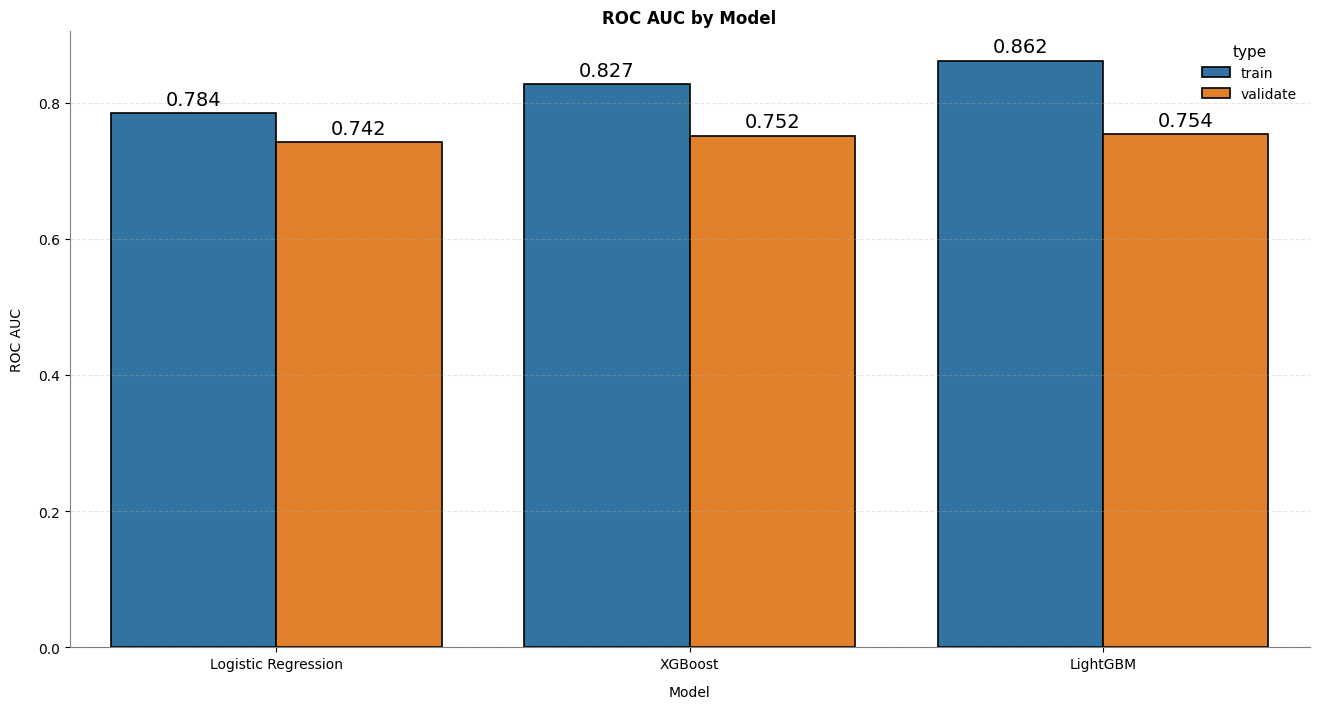

In [20]:
plotter = BarPlot(data)

x_axis_list = ['model']
y_axis_list = ['roc_auc']
hue_list = ['type']
ig, axes = plotter.multiple_plots(x_axis_list=x_axis_list, y_axis_list=y_axis_list,
                                     hue_list=hue_list, plots_each_row=1, readable_label=False, kwarg={})

# axes might be a single Axes or an array/list depending on how many plots
axes_list = np.atleast_1d(axes).flatten()

for ax in axes_list:
    ax.set_title("ROC AUC by Model", fontsize=12, fontweight='bold')
    ax.set_xlabel("Model", fontsize=10)
    ax.set_ylabel("ROC AUC", fontsize=10)
    for container in ax.containers:   # each hue group is usually a separate "container"
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=14)